In [1]:
# Enables postponed evaluation of type annotations (PEP 563).
# This allows referencing types before they are defined and cleaner type hints without quoting.
from __future__ import annotations

import operator  # Standard library operator module; operator.add is used as a reducer for list accumulation in State
import os
import re
from datetime import date, timedelta
from pathlib import Path
from typing import TypedDict, List, Optional, Literal, Annotated

# Pydantic is used for strict runtime validation and generating JSON schemas for LLM structured outputs
from pydantic import BaseModel, Field

# LangGraph core primitives: StateGraph manages state flow, START and END are sentinel nodes
from langgraph.graph import StateGraph, START, END
# Send is used to dynamically dispatch/fan-out parallel tasks to worker nodes (Map-Reduce pattern)
from langgraph.types import Send

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
# -----------------------------
# 1) Schemas (Pydantic Models)
# These models enforce strict data structure validation.
# When used with llm.with_structured_output(), Pydantic fields and their descriptions
# are converted into JSON schema parameters that instruct the LLM on what to produce.
# -----------------------------
class Task(BaseModel):
    id: int  # Unique integer ID (1, 2, 3...) to allow sorting parallel worker outputs back into order
    title: str

    # Ellipsis (...) indicates this field is strictly required (no default value)
    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    # min_length and max_length constrain the number of bullet points the LLM should generate
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=6,
        description="3–6 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(..., description="Target word count for this section (120–550).")

    # default_factory=list ensures a fresh empty list is created per instance (avoiding mutable default pitfalls)
    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    # Literal restricts the string value to one of these exact allowed categorizations
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]  # Ordered sequence of section writing tasks


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)  # Specific search queries if research is needed


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)


class ImageSpec(BaseModel):
    placeholder: str = Field(..., description="e.g. [[IMAGE_1]]")
    filename: str = Field(..., description="Save under images/, e.g. qkv_flow.png")
    alt: str
    caption: str
    prompt: str = Field(..., description="Prompt to send to the image model.")
    size: Literal["1024x1024", "1024x1536", "1536x1024"] = "1024x1024"
    quality: Literal["low", "medium", "high"] = "medium"


class GlobalImagePlan(BaseModel):
    md_with_placeholders: str  # The full markdown text with [[IMAGE_X]] tags injected at appropriate positions
    images: List[ImageSpec] = Field(default_factory=list)


In [3]:
# -----------------------------
# State Definition (TypedDict)
# In LangGraph, the State object flows between all nodes.
# By default, when a node returns a dictionary key, it OVERWRITES the previous value.
# The 'Annotated[..., operator.add]' below specifies a custom Reducer function,
# meaning new items are APPENDED instead of overwriting existing ones.
# -----------------------------
class State(TypedDict):
    topic: str  # The input topic/title provided by the user

    # routing / research
    mode: str                    # 'closed_book' | 'hybrid' | 'open_book'
    needs_research: bool         # Flag to branch to 'research' node or skip to 'orchestrator'
    queries: List[str]           # Generated search queries if research is required
    evidence: List[EvidenceItem] # List of verified web sources & snippets gathered
    plan: Optional[Plan]         # The master outline containing all section tasks

    # workers (Fan-out / Map phase)
    # IMPORTANT: Multiple worker nodes run concurrently. If this were a plain list, concurrent
    # writes would overwrite each other. Using Annotated[..., operator.add] tells LangGraph
    # to concatenate each worker's returned [(task_id, section_md)] list into the state.
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)

    # reducer / image processing (post-processing subgraph)
    merged_md: str            # Combined markdown text sorted by task_id
    md_with_placeholders: str # Markdown with [[IMAGE_1]], [[IMAGE_2]] insertion tags
    image_specs: List[dict]   # Serialized ImageSpec configurations for image generation

    final: str                # Final markdown with embedded images or fallback blocks


In [4]:
from dotenv import load_dotenv
load_dotenv(override=True)  # Load environment variables from .env file, allowing overrides for testing

True

In [5]:
# -----------------------------
# 2) LLM Initialization
# temperature=0 ensures deterministic, consistent outputs for structured schemas and routing
# -----------------------------
from langchain_google_genai import ChatGoogleGenerativeAI
llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite", temperature=0)


Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [6]:
# -----------------------------
# 3) Router (Decide upfront whether research is needed)
# Evaluates the topic nature to avoid redundant API search calls for evergreen topics,
# while ensuring timely topics gather fresh web facts.
# -----------------------------
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–10 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
    """
    Invokes LLM with RouterDecision schema to classify the topic.
    Returns a dict with updated mode, needs_research, and queries.
    """
    topic = state["topic"]
    # with_structured_output forces the model to respond strictly adhering to the RouterDecision Pydantic schema
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}"),
        ]
    )

    # Returning a dictionary updates the matching keys in the LangGraph State
    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }

def route_next(state: State) -> str:
    """
    Conditional edge router function.
    Returns the string name of the next node to transition to based on state['needs_research'].
    """
    return "research" if state["needs_research"] else "orchestrator"


In [7]:
# -----------------------------
# 4) Research (Tavily Search & Evidence Extraction)
# -----------------------------
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    """
    Helper function to query TavilySearchResults tool and normalize output keys into a uniform dictionary.
    """
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized: List[dict] = []
    # 'results or []' guards against None returns if search encounters an error
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:
    """
    Executes web searches for all queries, then asks LLM to filter, clean,
    and assemble an EvidencePack, followed by programmatic URL deduplication.
    """
    # Safely retrieve queries list
    queries = (state.get("queries", []) or [])
    max_results = 6

    raw_results: List[dict] = []

    # Execute search for each query and aggregate raw results
    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    # If no results found, return empty evidence
    if not raw_results:
        return {"evidence": []}

    # Pass aggregated raw results to LLM with structured output schema (EvidencePack)
    extractor = llm.with_structured_output(EvidencePack)
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results:\n{raw_results}"),
        ]
    )

    # Programmatic deduplication by URL using dictionary key assignment
    dedup = {}
    for e in pack.evidence:
        if e.url:
            dedup[e.url] = e

    return {"evidence": list(dedup.values())}


In [8]:
# -----------------------------
# 5) Orchestrator (Outline & Task Generation)
# Breaks down the blog post into 5-9 concrete, non-overlapping tasks.
# -----------------------------
ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 5–9 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) goal (1 sentence)
  2) 3–6 bullets that are concrete, specific, and non-overlapping
  3) target word count (120–550)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Ensure the overall plan includes at least 2 of these somewhere:
  * minimal code sketch / MWE (set requires_code=True for that section)
  * edge cases / failure modes
  * performance/cost considerations
  * security/privacy considerations (if relevant)
  * debugging/observability tips

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid:
  - Use evidence for up-to-date examples (models/tools/releases) in bullets.
  - Mark sections using fresh info as requires_research=True and requires_citations=True.
- Mode open_book:
  - Set blog_kind = "news_roundup".
  - Every section is about summarizing events + implications.
  - DO NOT include tutorial/how-to sections unless user explicitly asked for that.
  - If evidence is empty or insufficient, create a plan that transparently says "insufficient sources"
    and includes only what can be supported.

Output must strictly match the Plan schema.
"""

def orchestrator_node(state: State) -> dict:
    """
    Generates the blog Plan with structured tasks.
    Evidence items are serialized via model_dump() and truncated to the top 16 to avoid context blowup.
    """
    planner = llm.with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence][:16]}"
                )
            ),
        ]
    )

    return {"plan": plan}

# -----------------------------
# 6) Fanout (Map Step in Map-Reduce)
# In LangGraph, returning a list of Send('node_name', payload) from a conditional edge
# spawns N parallel branch executions of that node, each receiving its individual payload.
# -----------------------------
def fanout(state: State):
    """
    Iterates over all tasks in state['plan'].tasks and dispatches a dedicated 'worker' node for each.
    Each worker receives the specific task model, plus global context (topic, mode, plan, evidence).
    """
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),  # Convert Pydantic Task model to dict for serializable transport
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]


In [9]:
# -----------------------------
# 7) Worker (Writes one individual section in parallel)
# -----------------------------
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:
    """
    Executes for a single task assigned via Send().
    Reconstructs Pydantic objects from payload dicts for type validation and convenience.
    Returns [(task.id, section_md)] which is concatenated into State['sections'] by operator.add.
    """
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    # Format bullet points into a clean markdown list for the prompt
    bullets_text = "\n- " + "\n- ".join(task.bullets)

    # Format available evidence items into a readable citation list
    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )

    result = llm.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    )
    # Extract text from the LangChain response structure (Gemini returns a list of content blocks)
    section_md = result.content[0]["text"]

    # CRITICAL: Returning a tuple of (task.id, section_md) ensures that after parallel execution,
    # sections can be sorted in correct logical order, regardless of which worker finishes first.
    return {"sections": [(task.id, section_md)]}


In [10]:
# ============================================================
# 8) ReducerWithImages (Post-Processing Subgraph)
# Sequence: merge_content -> decide_images -> generate_and_place_images
# Encapsulating these three steps into a Subgraph isolates image logic
# and keeps the main graph clean and modular.
# ============================================================
def merge_content(state: State) -> dict:
    """
    Reducer Step 1: Sorts collected sections by task_id to restore intended outline order,
    joins them with double newlines, and prepends the top-level H1 title.
    """
    plan = state["plan"]

    # Lambda sorts by task_id (x[0]), preserving sequential order from plan
    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    merged_md = f"# {plan.blog_title}\n\n{body}\n"
    return {"merged_md": merged_md}


DECIDE_IMAGES_SYSTEM = """You are an expert technical editor.
Decide if images/diagrams are needed for THIS blog.

Rules:
- Max 4 images total.
- Each image must materially improve understanding (diagram/flow/table-like visual).
- Insert placeholders exactly: [[IMAGE_1]], [[IMAGE_2]], [[IMAGE_3]], [[IMAGE_4]].
- If no images needed: md_with_placeholders must equal input and images=[].
- Avoid decorative images; prefer technical diagrams with short labels.
Return strictly GlobalImagePlan.
"""

def decide_images(state: State) -> dict:
    """
    Reducer Step 2: An editor LLM decides where technical diagrams/flowcharts would genuinely help.
    Injects exact placeholder tags [[IMAGE_1]], [[IMAGE_2]] into markdown and defines ImageSpec prompts.
    """
    planner = llm.with_structured_output(GlobalImagePlan)
    merged_md = state["merged_md"]
    plan = state["plan"]
    assert plan is not None, "Plan must exist before deciding images"

    image_plan = planner.invoke(
        [
            SystemMessage(content=DECIDE_IMAGES_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Topic: {state['topic']}\n\n"
                    "Insert placeholders + propose image prompts.\n\n"
                    f"{merged_md}"
                )
            ),
        ]
    )

    return {
        "md_with_placeholders": image_plan.md_with_placeholders,
        "image_specs": [img.model_dump() for img in image_plan.images],
    }


def _gemini_generate_image_bytes(prompt: str) -> bytes:
    """
    Calls Google GenAI SDK (google-genai) to generate image bytes using 'gemini-2.5-flash-image'.
    Returns raw binary PNG/JPEG bytes.
    """
    from google import genai
    from google.genai import types

    api_key = os.environ.get("GOOGLE_API_KEY")
    if not api_key:
        raise RuntimeError("GOOGLE_API_KEY is not set.")

    client = genai.Client(api_key=api_key)

    resp = client.models.generate_content(
        model="gemini-2.5-flash-image",
        contents=prompt,
        config=types.GenerateContentConfig(
            response_modalities=["IMAGE"],  # Requests binary image output instead of text
            safety_settings=[
                types.SafetySetting(
                    category="HARM_CATEGORY_DANGEROUS_CONTENT",
                    threshold="BLOCK_ONLY_HIGH",
                )
            ],
        ),
    )

    # SDK compatibility handling: Depending on SDK version, parts may reside on resp.parts
    # or resp.candidates[0].content.parts
    parts = getattr(resp, "parts", None)
    if not parts and getattr(resp, "candidates", None):
        try:
            parts = resp.candidates[0].content.parts
        except Exception:
            parts = None

    if not parts:
        raise RuntimeError("No image content returned (safety/quota/SDK change).")

    # Find the part containing inline binary data
    for part in parts:
        inline = getattr(part, "inline_data", None)
        if inline and getattr(inline, "data", None):
            return inline.data  # Raw bytes

    raise RuntimeError("No inline image bytes found in response.")

## helper function to generate images
def generate_and_place_images(state: State) -> dict:
    """
    Reducer Step 3: Generates image files, saves them under images/, and replaces [[IMAGE_X]]
    placeholders with Markdown image syntax. Implements graceful fallback if generation fails.
    Writes the final file as '<Blog Title>.md'.
    """
    plan = state["plan"]
    assert plan is not None

    # Prefer markdown with placeholders, fallback to merged_md if placeholder step produced none
    md = state.get("md_with_placeholders") or state["merged_md"]
    image_specs = state.get("image_specs", []) or []

    # Fast path: If no images requested, write merged markdown directly and return
    if not image_specs:
        filename = f"{plan.blog_title}.md"
        Path(filename).write_text(md, encoding="utf-8")
        return {"final": md}

    images_dir = Path("images")
    images_dir.mkdir(exist_ok=True)  # Create images directory if it does not exist

    for spec in image_specs:
        placeholder = spec["placeholder"]
        filename = spec["filename"]
        out_path = images_dir / filename

        # Idempotence optimization: generate image only if file does not already exist on disk
        if not out_path.exists():
            try:
                img_bytes = _gemini_generate_image_bytes(spec["prompt"])
                out_path.write_bytes(img_bytes)
            except Exception as e:
                # GRACEFUL FALLBACK: If generation fails (safety policy, quota, timeout),
                # replace placeholder with an informative markdown blockquote instead of crashing!
                prompt_block = (
                    f"> **[IMAGE GENERATION FAILED]** {spec.get('caption','')}\n>\n"
                    f"> **Alt:** {spec.get('alt','')}\n>\n"
                    f"> **Prompt:** {spec.get('prompt','')}\n>\n"
                    f"> **Error:** {e}\n"
                )
                md = md.replace(placeholder, prompt_block)
                continue

        # Replace placeholder string with standard Markdown image syntax and caption
        img_md = f"![{spec['alt']}](images/{filename})\n*{spec['caption']}*"
        md = md.replace(placeholder, img_md)

    # Persist the final blog post file to disk
    filename = f"{plan.blog_title}.md"
    Path(filename).write_text(md, encoding="utf-8")
    return {"final": md}


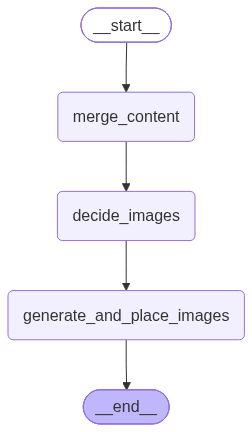

In [11]:
# -----------------------------
# Build Reducer Subgraph
# Why a Subgraph?
# Instead of adding 3 separate sequential nodes to the main graph,
# compiling them into an independent sub-graph creates a single re-usable unit of work:
# START -> merge_content -> decide_images -> generate_and_place_images -> END
# -----------------------------
reducer_graph = StateGraph(State)
reducer_graph.add_node("merge_content", merge_content)
reducer_graph.add_node("decide_images", decide_images)
reducer_graph.add_node("generate_and_place_images", generate_and_place_images)

# Define internal sequential pipeline flow
reducer_graph.add_edge(START, "merge_content")
reducer_graph.add_edge("merge_content", "decide_images")
reducer_graph.add_edge("decide_images", "generate_and_place_images")
reducer_graph.add_edge("generate_and_place_images", END)

# Compile the subgraph into a runnable component
reducer_subgraph = reducer_graph.compile()

reducer_subgraph


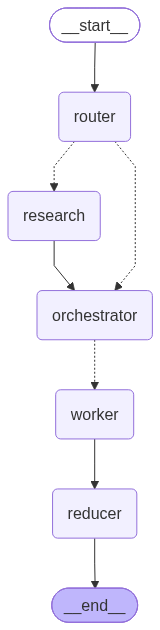

In [12]:
# -----------------------------
# 9) Build Main Graph Architecture
# -----------------------------
g = StateGraph(State)

# Register nodes (notice 'reducer' uses our compiled subgraph)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_subgraph)  # Nested subgraph registered as a standard node

# Entry point
g.add_edge(START, "router")

# Conditional Edge: Checks route_next (state['needs_research'])
# - True  -> transitions to 'research'
# - False -> skips directly to 'orchestrator'
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})

# From research, always proceed to orchestrator to build the outline
g.add_edge("research", "orchestrator")

# Dynamic Fanout / Map: orchestrator fans out N tasks to 'worker' nodes concurrently
g.add_conditional_edges("orchestrator", fanout, ["worker"])

# When all parallel workers finish, their outputs have been accumulated into State['sections']
# by the operator.add reducer, and execution transitions to the reducer subgraph
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

# Compile the complete executable StateGraph application
app = g.compile()
app


In [13]:
# -----------------------------
# 10) Runner Function
# Initializes graph state with safe defaults and executes the pipeline
# -----------------------------
def run(topic: str, as_of: Optional[str] = None):
    """
    Entrypoint to invoke the compiled LangGraph pipeline for any given blog topic.
    """
    if as_of is None:
        as_of = date.today().isoformat()

    # app.invoke passes the initial dictionary to State and executes until END
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "as_of": as_of,
            "recency_days": 7,
            "sections": [],             # Starts empty; parallel workers append via operator.add
            "merged_md": "",
            "md_with_placeholders": "",
            "image_specs": [],
            "final": "",
        }
    )

    return out


In [14]:
run("Langchain & Langgraph Ecosystem for bulding the agents with image generation and research capabilities")

/var/folders/ry/0dp2gqbj4nv8q6qbdj7z67700000gn/T/ipykernel_17562/1367072958.py:8: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=max_results)
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


{'topic': 'Langchain & Langgraph Ecosystem for bulding the agents with image generation and research capabilities',
 'mode': 'hybrid',
 'needs_research': True,
 'queries': ['LangGraph architecture for multi-agent systems with tool calling',
  'integrating DALL-E 3 or Stable Diffusion with LangChain agents',
  'LangGraph state management for research-based agent workflows',
  'best practices for building autonomous research agents using LangChain',
  'LangGraph vs LangChain for complex agentic orchestration',
  'implementing web search tools in LangChain agents for research tasks'],
 'evidence': [EvidenceItem(title='Fully local multi-agent systems with LangGraph', url='https://www.youtube.com/watch?v=4oC1ZKa9-Hs', published_at='2025-03-15', snippet='Discusses implementing multi-agent systems (swarm and supervisor) using LangGraph and local models like Qwen2.5-14b via Ollama, highlighting tool-calling capabilities.', source='YouTube'),
  EvidenceItem(title='Build multi-agent systems with